In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [9]:
arquivo = files.upload()

Saving lagarto.jpg to lagarto (1).jpg


Sobre a quantização: é o processo de reduzir a quantidade de níveis de intensidade ou cores possíveis que um pixel pode assumir.

Bits 	Níveis (2^bits)	O que significa

*   1 bit	- 2 níveis	só preto e branco (0 ou 255)
*   2 bits -	4 níveis	4 tons de cinza possíveis
*   4 bits - 16 níveis	16 tons de cinza possíveis
*   8 bits - 256 níveis	a imagem original, sem redução (todos os tons)

Qaunto menor a quantidade de bits, mais informação é perdida. Transições suaves ficam grotescas. No extremo de 1 bit, só sobra preto e branco puro: qualquer pixel abaixo da metade vira preto, qualquer um acima vira branco

CONVERSÃO TONS DE CINZA

array([[64, 64, 64, ..., 56, 56, 56],
       [64, 64, 64, ..., 56, 56, 56],
       [64, 64, 64, ..., 56, 56, 56],
       ...,
       [52, 61, 62, ..., 63, 39, 25],
       [47, 61, 65, ..., 65, 41, 27],
       [49, 59, 62, ..., 67, 43, 29]], dtype=uint8)
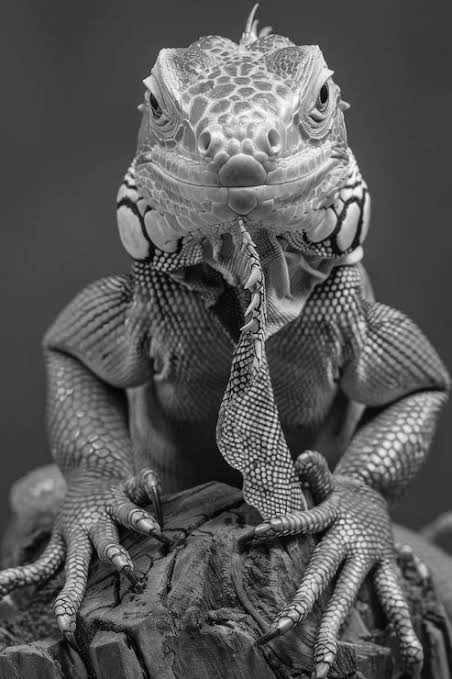

In [10]:
img = cv2.imread('/content/lagarto.jpg')
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_gray

QUANTIZAÇÃO

In [11]:
def quantizar_imagem(imagem, bits):
    niveis = 2 ** bits

    # Passo 1: normaliza os pixels para o intervalo [0, niveis-1]
    imagem_normalizada = imagem.astype(np.float32) / 255.0
    imagem_niveis = np.floor(imagem_normalizada * niveis)

    # Garante que não ultrapasse o nível máximo (caso o pixel seja 255)
    imagem_niveis = np.clip(imagem_niveis, 0, niveis - 1)

    # Passo 2: reescala de volta para [0, 255] para exibição
    imagem_quantizada = imagem_niveis * (255 / (niveis - 1))

    return imagem_quantizada.astype(np.uint8)

In [12]:
img_1bit = quantizar_imagem(img_gray, 1)
img_2bit = quantizar_imagem(img_gray, 2)
img_4bit = quantizar_imagem(img_gray, 4)
img_8bit = quantizar_imagem(img_gray, 8)

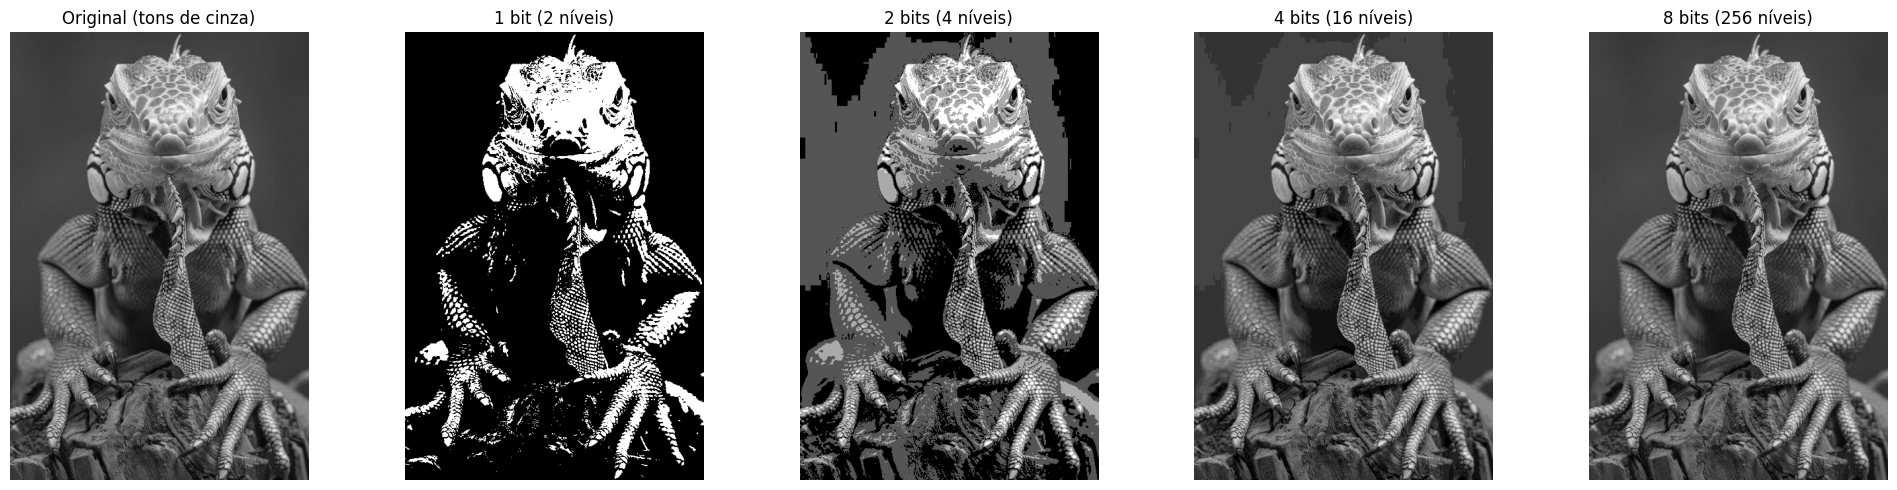

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title('Original (tons de cinza)')
axes[0].axis('off')

axes[1].imshow(img_1bit, cmap='gray')
axes[1].set_title('1 bit (2 níveis)')
axes[1].axis('off')

axes[2].imshow(img_2bit, cmap='gray')
axes[2].set_title('2 bits (4 níveis)')
axes[2].axis('off')

axes[3].imshow(img_4bit, cmap='gray')
axes[3].set_title('4 bits (16 níveis)')
axes[3].axis('off')

axes[4].imshow(img_8bit, cmap='gray')
axes[4].set_title('8 bits (256 níveis)')
axes[4].axis('off')

plt.tight_layout()
plt.savefig('quantizacao.png', dpi=150, bbox_inches='tight')
plt.show()